<a href="https://colab.research.google.com/github/srabani-khuntia/Machine-Learning-Lab/blob/main/Assignment-5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT - 5: Model Comparison & Best Subset Selection**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.feature_selection import mutual_info_classif

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    accuracy_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    balanced_accuracy_score
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Loading the classification dataset
from google.colab import files

uploaded = files.upload()
campus_df = pd.read_csv('campus_preprocessed.csv')

print("Dataset loaded successfully!")

Saving campus_preprocessed.csv to campus_preprocessed.csv
Dataset loaded successfully!


In [ ]:
# Separating independent and dependent variables
X = campus_df.drop(columns=['placed'])
y = campus_df['placed']

# Ensuring all predictor columns are numerical
print("All features are numerical:", X.select_dtypes(exclude=np.number).empty)

print("Number of Features:", X.shape[1])
print("Target Variable:", y.name)

print("\nFeature Names:")
print(X.columns.tolist())

All features are numerical: True
Number of Features: 33
Target Variable: placed

Feature Names:
['age', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'mba_percentage', 'internships_count', 'projects_count', 'certifications_count', 'technical_skills_score', 'soft_skills_score', 'aptitude_score', 'communication_score', 'work_experience_months', 'leadership_roles', 'extracurricular_activities', 'backlogs', 'gender_Male', 'gender_Other', 'city_tier_Tier 2', 'city_tier_Tier 3', 'ssc_board_ICSE', 'ssc_board_State', 'hsc_board_ICSE', 'hsc_board_State', 'hsc_stream_Commerce', 'hsc_stream_Science', 'degree_field_Business', 'degree_field_Engineering', 'degree_field_Other', 'degree_field_Science', 'specialization_Marketing & Finance', 'specialization_Marketing & HR', 'specialization_Not Applicable']


In [ ]:
# Splitting the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Dataset Shape:", X_train.shape)
print("Testing Dataset Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Dataset Shape: (80000, 33)
Testing Dataset Shape: (20000, 33)

Training Target Distribution:
placed
1    67546
0    12454
Name: count, dtype: int64

Testing Target Distribution:
placed
1    16886
0     3114
Name: count, dtype: int64


In [ ]:
# Defining classification models

classifiers = {
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(n_neighbors=5))
    ]),

    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    'LDA': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LinearDiscriminantAnalysis())
    ]),

    'SVC': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', SVC(
            kernel='linear',
            random_state=42
        ))
    ])
}

print("Classification models defined successfully!")

Classification models defined successfully!


In [ ]:
# Creating a stratified sample for SVC
X_svc_train, _, y_svc_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    random_state=42,
    stratify=y_train
)

# Dictionaries to store predictions and scores
trained_models = {}
predictions = {}
prediction_scores = {}

for name, model in classifiers.items():

    print(f"Training {name}...")

    if name == 'SVC':
        model.fit(X_svc_train, y_svc_train)
    else:
        model.fit(X_train, y_train)

    trained_models[name] = model

    # Predicting test labels
    predictions[name] = model.predict(X_test)

    # Obtaining scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        prediction_scores[name] = model.predict_proba(X_test)[:, 1]
    else:
        prediction_scores[name] = model.decision_function(X_test)

    print(f"{name} trained successfully!\n")

Training KNN...
KNN trained successfully!

Training Logistic Regression...
Logistic Regression trained successfully!

Training LDA...
LDA trained successfully!

Training SVC...
SVC trained successfully!



In [ ]:
# Creating a dictionary to store evaluation metrics
results = {}

for name in classifiers:

    y_pred = predictions[name]
    y_score = prediction_scores[name]

    results[name] = {
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_score),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred)
    }

# Converting results into a DataFrame
performance_df = pd.DataFrame(results).T

print("Classification Performance Comparison:")
display(performance_df.round(4))

Classification Performance Comparison:


,Precision,Recall,Accuracy,F1-Score,ROC-AUC,Balanced Accuracy
KNN,0.8607,0.9638,0.8377,0.9093,0.6943,0.5588
Logistic Regression,0.8756,0.9703,0.8586,0.9206,0.8419,0.6115
LDA,0.8762,0.9678,0.8574,0.9197,0.8399,0.6130
SVC,0.8443,1.0000,0.8443,0.9156,0.8362,0.5000


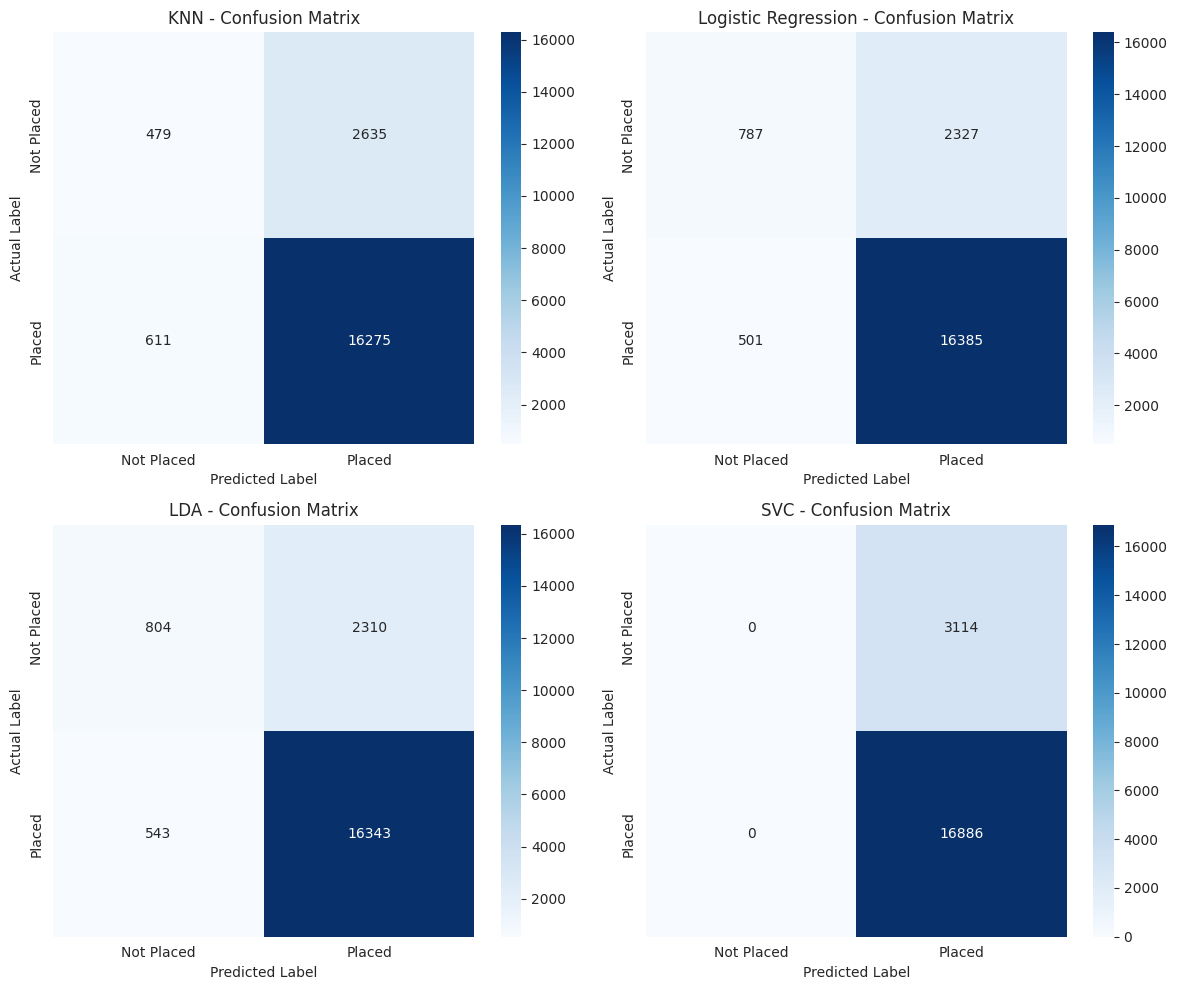

In [ ]:
# Displaying confusion matrices for all classifiers

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, name in zip(axes, classifiers):

    cm = confusion_matrix(y_test, predictions[name])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Placed', 'Placed'],
        yticklabels=['Not Placed', 'Placed'],
        ax=ax
    )

    ax.set_title(f'{name} - Confusion Matrix')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

##### **1.Plot the bar diagram of classifiers’ Confusion Matrix performance of KNN classifier, Logistic regression, LDA, and SVC. Find which one best.**

Confusion Matrix Values:


,TN,FP,FN,TP
KNN,479,2635,611,16275
Logistic Regression,787,2327,501,16385
LDA,804,2310,543,16343
SVC,0,3114,0,16886


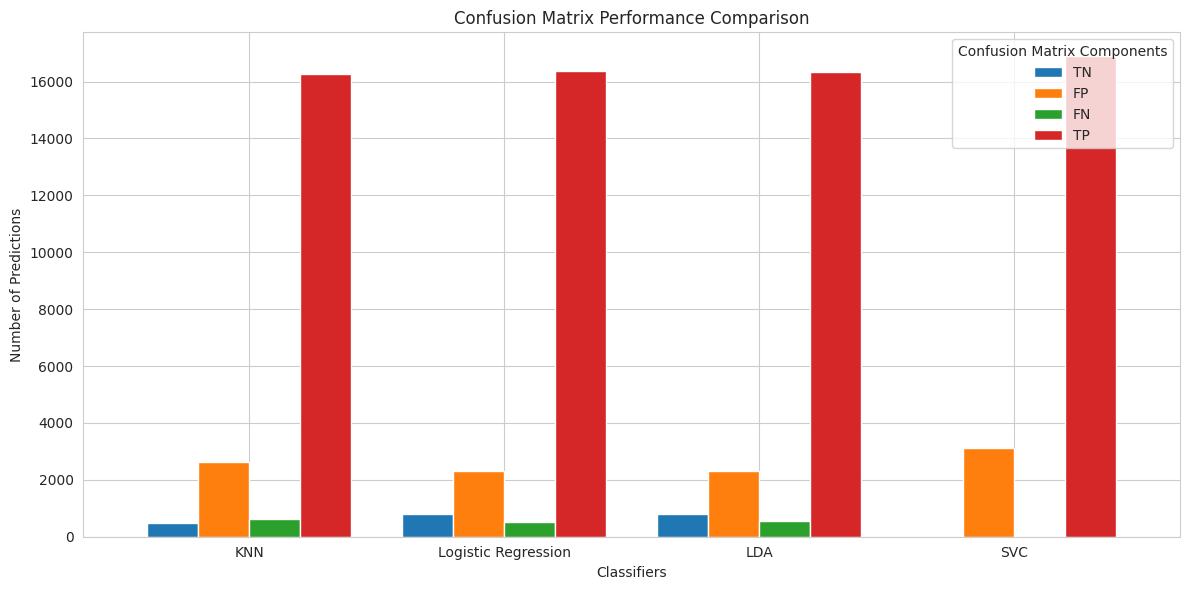

Best Classifier based on Balanced Accuracy: LDA
Balanced Accuracy: 0.613


In [ ]:
# Extracting confusion matrix values
cm_results = {}

for name in classifiers:

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions[name]
    ).ravel()

    cm_results[name] = {
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    }

cm_df = pd.DataFrame(cm_results).T

print("Confusion Matrix Values:")
display(cm_df)

# Plotting confusion matrix components
cm_df.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title("Confusion Matrix Performance Comparison")
plt.xlabel("Classifiers")
plt.ylabel("Number of Predictions")
plt.xticks(rotation=0)
plt.legend(title="Confusion Matrix Components")
plt.tight_layout()
plt.show()

# Identifying the classifier with the highest balanced accuracy
best_cm_model = performance_df['Balanced Accuracy'].idxmax()

print("Best Classifier based on Balanced Accuracy:", best_cm_model)
print(
    "Balanced Accuracy:",
    round(performance_df.loc[best_cm_model, 'Balanced Accuracy'], 4)
)

##### **2.Plot the bar diagram of classifiers’ Precision performance of KNN classifier, Logistic regression, LDA, and SVC. Find which one best.**

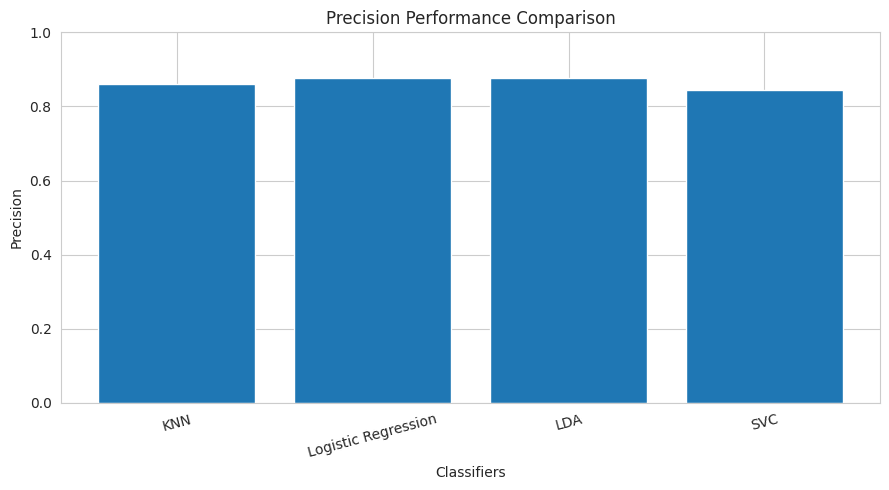

Best Classifier based on Precision: LDA
Highest Precision: 0.8762


In [ ]:
# Extracting precision scores
precision_values = performance_df['Precision']

# Plotting precision comparison
plt.figure(figsize=(9, 5))

plt.bar(
    precision_values.index,
    precision_values.values
)

plt.title("Precision Performance Comparison")
plt.xlabel("Classifiers")
plt.ylabel("Precision")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Identifying the best classifier
best_precision_model = precision_values.idxmax()

print("Best Classifier based on Precision:", best_precision_model)
print("Highest Precision:", round(precision_values.max(), 4))

##### **3. Plot the bar diagram of classifiers’ Recall, accuracy, f1-score and ROC curve performance of KNN classifier, Logistic regression, LDA, and SVC. Find which one best.**

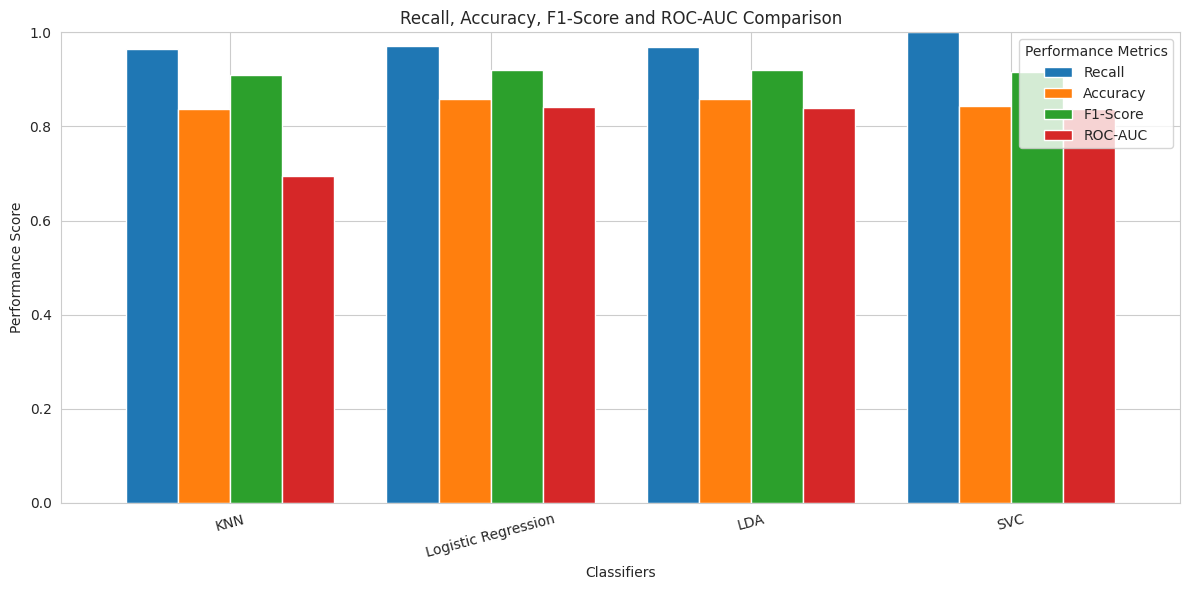

Best Classifier for Each Performance Metric:

Recall: SVC (1.0000)
Accuracy: Logistic Regression (0.8586)
F1-Score: Logistic Regression (0.9206)
ROC-AUC: Logistic Regression (0.8419)


In [ ]:
# Selecting the required performance metrics
selected_metrics = performance_df[
    ['Recall', 'Accuracy', 'F1-Score', 'ROC-AUC']
]

# Plotting comparison
selected_metrics.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title("Recall, Accuracy, F1-Score and ROC-AUC Comparison")
plt.xlabel("Classifiers")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Performance Metrics")
plt.tight_layout()
plt.show()

# Identifying the best classifier for each metric
print("Best Classifier for Each Performance Metric:\n")

for metric in selected_metrics.columns:
    best_model = selected_metrics[metric].idxmax()

    print(
        f"{metric}: {best_model} "
        f"({selected_metrics.loc[best_model, metric]:.4f})"
    )

##### **4. Plot the bar diagram of classifiers’ accuracy, f1-score and ROC curve performance of KNN classifier, Logistic regression, LDA, and SVC. Find which one best.**

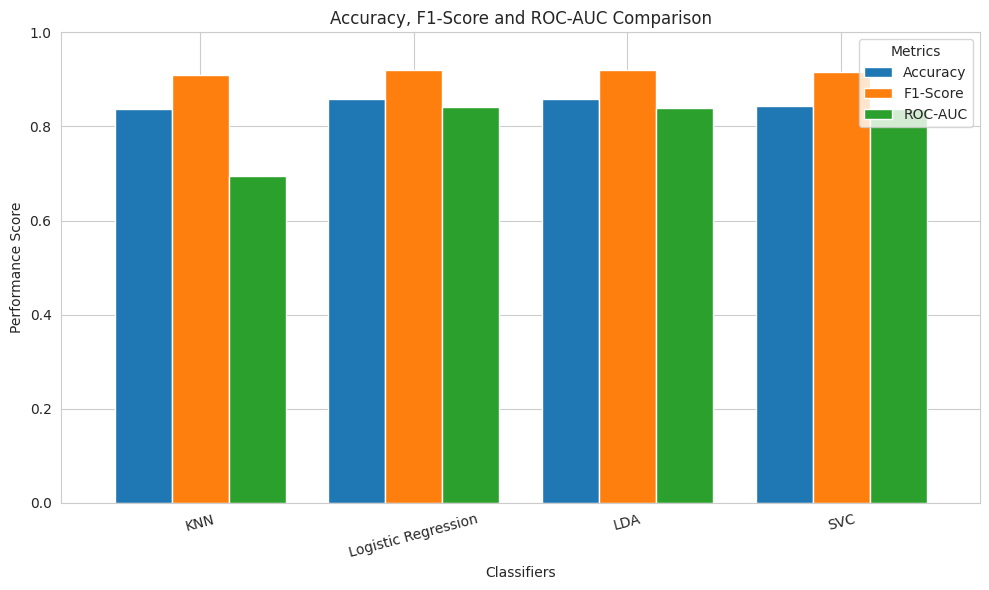

Best Accuracy: Logistic Regression
Best F1-Score: Logistic Regression
Best ROC-AUC: Logistic Regression


In [ ]:
# Selecting the required metrics
q4_metrics = performance_df[
    ['Accuracy', 'F1-Score', 'ROC-AUC']
]

# Plotting performance comparison
q4_metrics.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.8
)

plt.title("Accuracy, F1-Score and ROC-AUC Comparison")
plt.xlabel("Classifiers")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

# Best classifier for each metric
for metric in q4_metrics.columns:
    print(
        f"Best {metric}: {q4_metrics[metric].idxmax()}"
    )

##### **5.	Plot the bar diagram of classifiers’ f1-score and ROC curve performance of KNN classifier, Logistic regression, LDA, and SVC. Find which one best.**

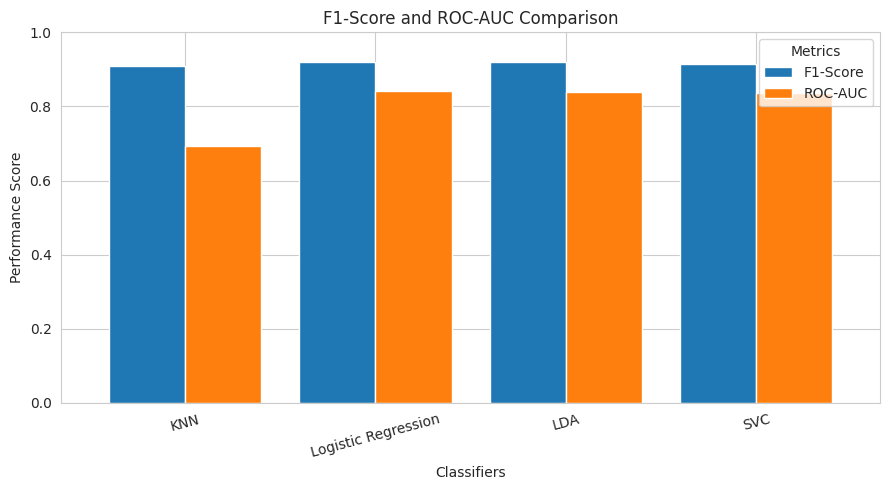

Best F1-Score Model: Logistic Regression
Best ROC-AUC Model: Logistic Regression


In [ ]:
# Selecting F1-score and ROC-AUC
q5_metrics = performance_df[
    ['F1-Score', 'ROC-AUC']
]

# Plotting comparison
q5_metrics.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.8
)

plt.title("F1-Score and ROC-AUC Comparison")
plt.xlabel("Classifiers")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

# Identifying best performers
print("Best F1-Score Model:", q5_metrics['F1-Score'].idxmax())
print("Best ROC-AUC Model:", q5_metrics['ROC-AUC'].idxmax())

##### **6.  Plot the bar diagram of classifiers’ ROC curve performance of KNN classifier, Logistic regression, LDA, and SVC. Find which one best.**

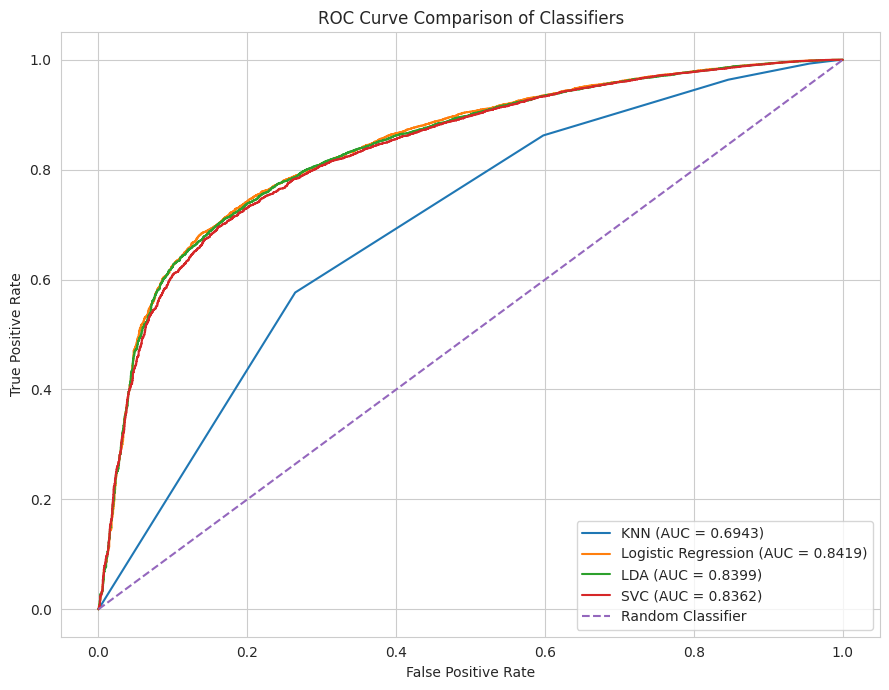

Best Classifier based on ROC-AUC: Logistic Regression
Highest ROC-AUC: 0.8419


In [ ]:
plt.figure(figsize=(9, 7))

for name in classifiers:

    fpr, tpr, thresholds = roc_curve(
        y_test,
        prediction_scores[name]
    )

    auc_value = roc_auc_score(
        y_test,
        prediction_scores[name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title("ROC Curve Comparison of Classifiers")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

# Identifying the best ROC-AUC performer
best_roc_model = performance_df['ROC-AUC'].idxmax()

print("Best Classifier based on ROC-AUC:", best_roc_model)
print("Highest ROC-AUC:", round(performance_df.loc[best_roc_model, 'ROC-AUC'], 4))

##### **7.	Plot the bar diagram for the best performers in Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve performances.**

Best Performing Classifiers:


,Best Classifier,Score
Balanced Accuracy,LDA,0.613016
Precision,LDA,0.876159
Recall,SVC,1.0
Accuracy,Logistic Regression,0.8586
F1-Score,Logistic Regression,0.920557
ROC-AUC,Logistic Regression,0.841934


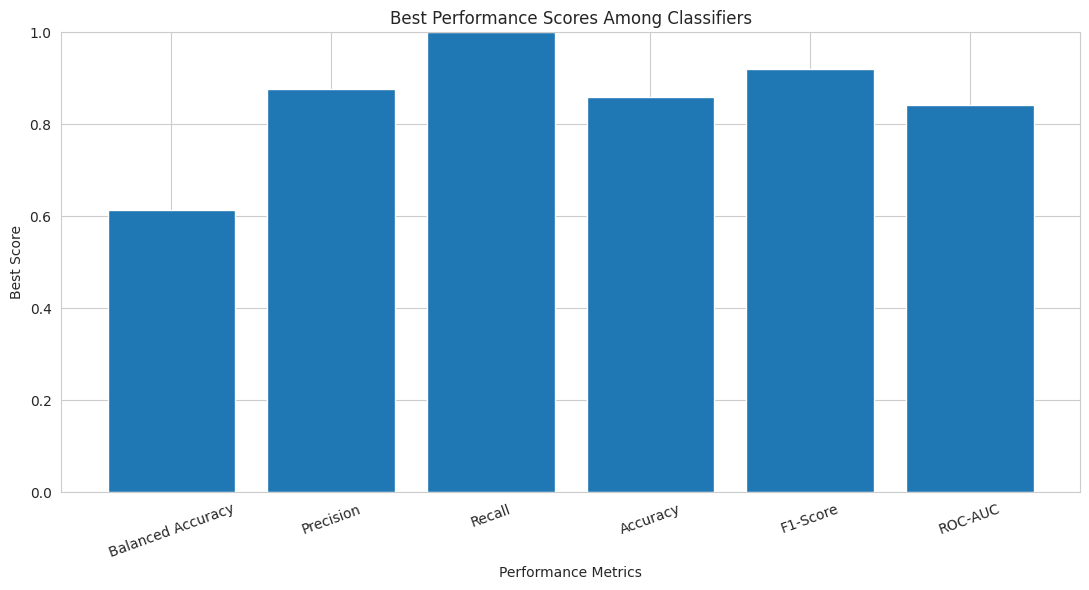

In [ ]:
# Identifying the best classifier for each metric
metrics_to_compare = [
    'Balanced Accuracy',
    'Precision',
    'Recall',
    'Accuracy',
    'F1-Score',
    'ROC-AUC'
]

best_performers = {}

for metric in metrics_to_compare:

    best_model = performance_df[metric].idxmax()

    best_performers[metric] = {
        'Best Classifier': best_model,
        'Score': performance_df.loc[best_model, metric]
    }

best_performers_df = pd.DataFrame(best_performers).T

print("Best Performing Classifiers:")
display(best_performers_df.round(4))

# Plotting the best performance scores
plt.figure(figsize=(11, 6))

plt.bar(
    best_performers_df.index,
    best_performers_df['Score']
)

plt.title("Best Performance Scores Among Classifiers")
plt.xlabel("Performance Metrics")
plt.ylabel("Best Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
print("CLASSIFICATION PERFORMANCE CONCLUSION\n")

for metric in metrics_to_compare:

    model_name = best_performers_df.loc[metric, 'Best Classifier']
    score = best_performers_df.loc[metric, 'Score']

    print(f"{metric}: {model_name} with a score of {score:.4f}")

print("\nOverall Performance Table:")
display(performance_df.round(4))

CLASSIFICATION PERFORMANCE CONCLUSION

Balanced Accuracy: LDA with a score of 0.6130
Precision: LDA with a score of 0.8762
Recall: SVC with a score of 1.0000
Accuracy: Logistic Regression with a score of 0.8586
F1-Score: Logistic Regression with a score of 0.9206
ROC-AUC: Logistic Regression with a score of 0.8419

Overall Performance Table:


,Precision,Recall,Accuracy,F1-Score,ROC-AUC,Balanced Accuracy
KNN,0.8607,0.9638,0.8377,0.9093,0.6943,0.5588
Logistic Regression,0.8756,0.9703,0.8586,0.9206,0.8419,0.6115
LDA,0.8762,0.9678,0.8574,0.9197,0.8399,0.6130
SVC,0.8443,1.0000,0.8443,0.9156,0.8362,0.5000


In [ ]:
# Creating a stratified sample from the training dataset
X_bss, _, y_bss, _ = train_test_split(
    X_train,
    y_train,
    train_size=2500,
    random_state=42,
    stratify=y_train
)

print("BSS Training Sample Shape:", X_bss.shape)
print("BSS Target Shape:", y_bss.shape)

BSS Training Sample Shape: (2500, 33)
BSS Target Shape: (2500,)


In [ ]:
# Calculating mutual information scores
mi_scores = mutual_info_classif(
    X_bss,
    y_bss,
    random_state=42
)

# Creating a feature importance DataFrame
mi_df = pd.DataFrame({
    'Feature': X_bss.columns,
    'Mutual Information': mi_scores
})

# Sorting features by mutual information
mi_df = mi_df.sort_values(
    by='Mutual Information',
    ascending=False
).reset_index(drop=True)

print("Feature Ranking based on Mutual Information:")
display(mi_df)

# Selecting the top 7 candidate features
candidate_features = mi_df.head(7)['Feature'].tolist()

print("\nCandidate Features for Best Subset Selection:")
for feature in candidate_features:
    print(feature)

print("\nNumber of Candidate Features:", len(candidate_features))

Feature Ranking based on Mutual Information:


,Feature,Mutual Information
0,soft_skills_score,0.032732
1,communication_score,0.029735
2,backlogs,0.024760
3,technical_skills_score,0.019785
4,ssc_percentage,0.018055
5,internships_count,0.016291
6,hsc_percentage,0.010794
7,degree_percentage,0.010142
8,hsc_stream_Science,0.009612
9,ssc_board_State,0.005088



Candidate Features for Best Subset Selection:
soft_skills_score
communication_score
backlogs
technical_skills_score
ssc_percentage
internships_count
hsc_percentage

Number of Candidate Features: 7


In [ ]:
# Defining classifiers for BSS

bss_classifiers = {
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(n_neighbors=5))
    ]),

    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    'LDA': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LinearDiscriminantAnalysis())
    ]),

    'SVC': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', SVC(
            kernel='linear',
            random_state=42
        ))
    ])
}

# Defining 5-fold stratified cross-validation
bss_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("BSS classifiers and 5-fold cross-validation defined successfully!")

BSS classifiers and 5-fold cross-validation defined successfully!


In [ ]:
def best_subset_selection(
    estimator,
    X_data,
    y_data,
    candidate_features,
    cv
):

    size_wise_results = []

    total_features = len(candidate_features)

    # Evaluating subsets of different sizes
    for k in range(1, total_features + 1):

        best_accuracy = -1
        best_subset = None

        # Generating all combinations containing exactly k features
        for subset in combinations(candidate_features, k):

            subset = list(subset)

            # Selecting the current feature subset
            X_subset = X_data[subset]

            # Performing 5-fold cross-validation
            scores = cross_val_score(
                estimator,
                X_subset,
                y_data,
                cv=cv,
                scoring='accuracy',
                n_jobs=-1
            )

            mean_accuracy = scores.mean()

            # Retaining the best subset of the current size
            if mean_accuracy > best_accuracy:

                best_accuracy = mean_accuracy
                best_subset = subset

        size_wise_results.append({
            'Number of Features': k,
            'Feature Subset': best_subset,
            'CV Accuracy': best_accuracy
        })

        print(
            f"Completed subset size {k}: "
            f"CV Accuracy = {best_accuracy:.4f}"
        )

    # Converting size-wise results into a DataFrame
    size_wise_df = pd.DataFrame(size_wise_results)

    # Selecting the overall best subset
    best_row = size_wise_df.loc[
        size_wise_df['CV Accuracy'].idxmax()
    ]

    best_features = best_row['Feature Subset']

    return size_wise_df, best_features

##### **8.  Implement the best subset selection approach for feature selection using k- fold cross validation approach for KNN where k = 5. Display size wise best with number of features, features subset, cross validation accuracy. Show the performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve performances of best features subset.**

In [ ]:
print("BEST SUBSET SELECTION - KNN\n")

knn_bss_results, knn_best_features = best_subset_selection(
    estimator=bss_classifiers['KNN'],
    X_data=X_bss,
    y_data=y_bss,
    candidate_features=candidate_features,
    cv=bss_cv
)

print("\nSize-wise Best Subsets for KNN:")
display(knn_bss_results)

print("\nBest Feature Subset for KNN:")
print(knn_best_features)

print("\nNumber of Selected Features:", len(knn_best_features))

print(
    "Best Cross-Validation Accuracy:",
    round(knn_bss_results['CV Accuracy'].max(), 4)
)

BEST SUBSET SELECTION - KNN

Completed subset size 1: CV Accuracy = 0.8304
Completed subset size 2: CV Accuracy = 0.8364
Completed subset size 3: CV Accuracy = 0.8396
Completed subset size 4: CV Accuracy = 0.8460
Completed subset size 5: CV Accuracy = 0.8448
Completed subset size 6: CV Accuracy = 0.8444
Completed subset size 7: CV Accuracy = 0.8384

Size-wise Best Subsets for KNN:


,Number of Features,Feature Subset,CV Accuracy
0,1,[communication_score],0.8304
1,2,"[backlogs, technical_skills_score]",0.8364
2,3,"[soft_skills_score, backlogs, ssc_percentage]",0.8396
3,4,"[communication_score, backlogs, internships_co...",0.8460
4,5,"[communication_score, backlogs, technical_skil...",0.8448
5,6,"[soft_skills_score, communication_score, backl...",0.8444
6,7,"[soft_skills_score, communication_score, backl...",0.8384



Best Feature Subset for KNN:
['communication_score', 'backlogs', 'internships_count', 'hsc_percentage']

Number of Selected Features: 4
Best Cross-Validation Accuracy: 0.846


##### **9.  Implement the best subset selection approach for feature selection using k- fold cross validation approach for Logistic regression where k = 5. Display size wise best with number of features, features subset, cross validation accuracy. Show the performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve performances of best features subset.**

In [ ]:
print("BEST SUBSET SELECTION - LOGISTIC REGRESSION\n")

lr_bss_results, lr_best_features = best_subset_selection(
    estimator=bss_classifiers['Logistic Regression'],
    X_data=X_bss,
    y_data=y_bss,
    candidate_features=candidate_features,
    cv=bss_cv
)

print("\nSize-wise Best Subsets for Logistic Regression:")
display(lr_bss_results)

print("\nBest Feature Subset for Logistic Regression:")
print(lr_best_features)

print("\nNumber of Selected Features:", len(lr_best_features))

print(
    "Best Cross-Validation Accuracy:",
    round(lr_bss_results['CV Accuracy'].max(), 4)
)

BEST SUBSET SELECTION - LOGISTIC REGRESSION

Completed subset size 1: CV Accuracy = 0.8456
Completed subset size 2: CV Accuracy = 0.8520
Completed subset size 3: CV Accuracy = 0.8548
Completed subset size 4: CV Accuracy = 0.8560
Completed subset size 5: CV Accuracy = 0.8544
Completed subset size 6: CV Accuracy = 0.8536
Completed subset size 7: CV Accuracy = 0.8516

Size-wise Best Subsets for Logistic Regression:


,Number of Features,Feature Subset,CV Accuracy
0,1,[backlogs],0.8456
1,2,"[soft_skills_score, backlogs]",0.8520
2,3,"[soft_skills_score, backlogs, hsc_percentage]",0.8548
3,4,"[soft_skills_score, communication_score, backl...",0.8560
4,5,"[backlogs, technical_skills_score, ssc_percent...",0.8544
5,6,"[soft_skills_score, communication_score, backl...",0.8536
6,7,"[soft_skills_score, communication_score, backl...",0.8516



Best Feature Subset for Logistic Regression:
['soft_skills_score', 'communication_score', 'backlogs', 'hsc_percentage']

Number of Selected Features: 4
Best Cross-Validation Accuracy: 0.856


##### **10. Implement the best subset selection approach for feature selection using k- fold cross validation approach for LDA where k = 5. Display size wise best with number of features, features subset, cross validation accuracy. Show the performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve performances of best features subset.**

In [ ]:
print("BEST SUBSET SELECTION - LDA\n")

lda_bss_results, lda_best_features = best_subset_selection(
    estimator=bss_classifiers['LDA'],
    X_data=X_bss,
    y_data=y_bss,
    candidate_features=candidate_features,
    cv=bss_cv
)

print("\nSize-wise Best Subsets for LDA:")
display(lda_bss_results)

print("\nBest Feature Subset for LDA:")
print(lda_best_features)

print("\nNumber of Selected Features:", len(lda_best_features))

print(
    "Best Cross-Validation Accuracy:",
    round(lda_bss_results['CV Accuracy'].max(), 4)
)

BEST SUBSET SELECTION - LDA

Completed subset size 1: CV Accuracy = 0.8444
Completed subset size 2: CV Accuracy = 0.8496
Completed subset size 3: CV Accuracy = 0.8544
Completed subset size 4: CV Accuracy = 0.8540
Completed subset size 5: CV Accuracy = 0.8540
Completed subset size 6: CV Accuracy = 0.8524
Completed subset size 7: CV Accuracy = 0.8516

Size-wise Best Subsets for LDA:


,Number of Features,Feature Subset,CV Accuracy
0,1,[soft_skills_score],0.8444
1,2,"[soft_skills_score, backlogs]",0.8496
2,3,"[communication_score, backlogs, hsc_percentage]",0.8544
3,4,"[soft_skills_score, communication_score, backl...",0.8540
4,5,"[backlogs, technical_skills_score, ssc_percent...",0.8540
5,6,"[soft_skills_score, communication_score, backl...",0.8524
6,7,"[soft_skills_score, communication_score, backl...",0.8516



Best Feature Subset for LDA:
['communication_score', 'backlogs', 'hsc_percentage']

Number of Selected Features: 3
Best Cross-Validation Accuracy: 0.8544


##### **11. Implement the best subset selection approach for feature selection using k- fold cross validation approach for SVC where k = 5. Display size wise best with number of features, features subset, cross validation accuracy. Show the performances such as Confusion Matrix, Precision, Recall, accuracy, f1-score and ROC curve performances of best features subset.**

In [ ]:
print("BEST SUBSET SELECTION - SVC\n")

svc_bss_results, svc_best_features = best_subset_selection(
    estimator=bss_classifiers['SVC'],
    X_data=X_bss,
    y_data=y_bss,
    candidate_features=candidate_features,
    cv=bss_cv
)

print("\nSize-wise Best Subsets for SVC:")
display(svc_bss_results)

print("\nBest Feature Subset for SVC:")
print(svc_best_features)

print("\nNumber of Selected Features:", len(svc_best_features))

print(
    "Best Cross-Validation Accuracy:",
    round(svc_bss_results['CV Accuracy'].max(), 4)
)

BEST SUBSET SELECTION - SVC

Completed subset size 1: CV Accuracy = 0.8444
Completed subset size 2: CV Accuracy = 0.8444
Completed subset size 3: CV Accuracy = 0.8444
Completed subset size 4: CV Accuracy = 0.8444
Completed subset size 5: CV Accuracy = 0.8444
Completed subset size 6: CV Accuracy = 0.8444
Completed subset size 7: CV Accuracy = 0.8444

Size-wise Best Subsets for SVC:


,Number of Features,Feature Subset,CV Accuracy
0,1,[soft_skills_score],0.8444
1,2,"[soft_skills_score, communication_score]",0.8444
2,3,"[soft_skills_score, communication_score, backl...",0.8444
3,4,"[soft_skills_score, communication_score, backl...",0.8444
4,5,"[soft_skills_score, communication_score, backl...",0.8444
5,6,"[soft_skills_score, communication_score, backl...",0.8444
6,7,"[soft_skills_score, communication_score, backl...",0.8444



Best Feature Subset for SVC:
['soft_skills_score']

Number of Selected Features: 1
Best Cross-Validation Accuracy: 0.8444


Size-wise Best Cross-Validation Accuracy:


,Number of Features,KNN,Logistic Regression,LDA,SVC
0,1,0.8304,0.8456,0.8444,0.8444
1,2,0.8364,0.8520,0.8496,0.8444
2,3,0.8396,0.8548,0.8544,0.8444
3,4,0.8460,0.8560,0.8540,0.8444
4,5,0.8448,0.8544,0.8540,0.8444
5,6,0.8444,0.8536,0.8524,0.8444
6,7,0.8384,0.8516,0.8516,0.8444


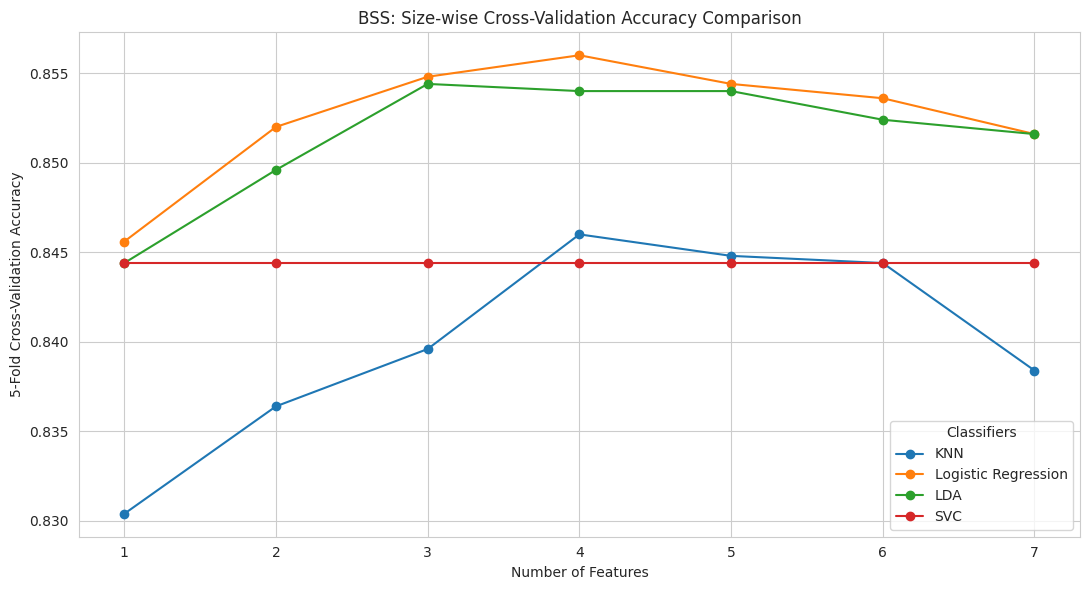

In [ ]:
# Collecting size-wise CV results
bss_comparison = pd.DataFrame({
    'Number of Features': range(1, len(candidate_features) + 1),
    'KNN': knn_bss_results['CV Accuracy'],
    'Logistic Regression': lr_bss_results['CV Accuracy'],
    'LDA': lda_bss_results['CV Accuracy'],
    'SVC': svc_bss_results['CV Accuracy']
})

print("Size-wise Best Cross-Validation Accuracy:")
display(bss_comparison.round(4))

# Plotting the comparison
bss_comparison.set_index(
    'Number of Features'
).plot(
    kind='line',
    marker='o',
    figsize=(11, 6)
)

plt.title("BSS: Size-wise Cross-Validation Accuracy Comparison")
plt.xlabel("Number of Features")
plt.ylabel("5-Fold Cross-Validation Accuracy")
plt.xticks(range(1, len(candidate_features) + 1))
plt.legend(title="Classifiers")
plt.tight_layout()
plt.show()

In [ ]:
# Storing the best feature subsets
best_feature_subsets = {
    'KNN': knn_best_features,
    'Logistic Regression': lr_best_features,
    'LDA': lda_best_features,
    'SVC': svc_best_features
}

# Dictionaries to store final models and predictions
final_bss_models = {}
bss_predictions = {}
bss_prediction_scores = {}

for name, features in best_feature_subsets.items():

    print(f"Training {name} using its best feature subset...")

    model = bss_classifiers[name]

    # SVC uses the same stratified training sample as the baseline model
    if name == 'SVC':
        model.fit(
            X_svc_train[features],
            y_svc_train
        )
    else:
        model.fit(
            X_train[features],
            y_train
        )

    final_bss_models[name] = model

    # Predicting test labels using selected features
    bss_predictions[name] = model.predict(
        X_test[features]
    )

    # Obtaining scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        bss_prediction_scores[name] = model.predict_proba(
            X_test[features]
        )[:, 1]
    else:
        bss_prediction_scores[name] = model.decision_function(
            X_test[features]
        )

    print(f"{name} trained successfully!")
    print("Selected Features:", features)
    print()

Training KNN using its best feature subset...
KNN trained successfully!
Selected Features: ['communication_score', 'backlogs', 'internships_count', 'hsc_percentage']

Training Logistic Regression using its best feature subset...
Logistic Regression trained successfully!
Selected Features: ['soft_skills_score', 'communication_score', 'backlogs', 'hsc_percentage']

Training LDA using its best feature subset...
LDA trained successfully!
Selected Features: ['communication_score', 'backlogs', 'hsc_percentage']

Training SVC using its best feature subset...
SVC trained successfully!
Selected Features: ['soft_skills_score']



In [ ]:
# Calculating evaluation metrics after feature selection
bss_performance = {}

for name in best_feature_subsets:

    y_pred = bss_predictions[name]
    y_score = bss_prediction_scores[name]

    bss_performance[name] = {
        'Number of Features': len(best_feature_subsets[name]),
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'Accuracy': accuracy_score(
            y_test, y_pred
        ),
        'F1-Score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(
            y_test, y_score
        ),
        'Balanced Accuracy': balanced_accuracy_score(
            y_test, y_pred
        )
    }

bss_performance_df = pd.DataFrame(
    bss_performance
).T

print("Performance of Classifiers After Best Subset Selection:")
display(bss_performance_df.round(4))

Performance of Classifiers After Best Subset Selection:


,Number of Features,Precision,Recall,Accuracy,F1-Score,ROC-AUC,Balanced Accuracy
KNN,4.0,0.8690,0.9469,0.8346,0.9063,0.7032,0.5865
Logistic Regression,4.0,0.8636,0.9780,0.8510,0.9173,0.7851,0.5703
LDA,3.0,0.8673,0.9702,0.8495,0.9159,0.7794,0.5826
SVC,1.0,0.8443,1.0000,0.8443,0.9156,0.5332,0.5000


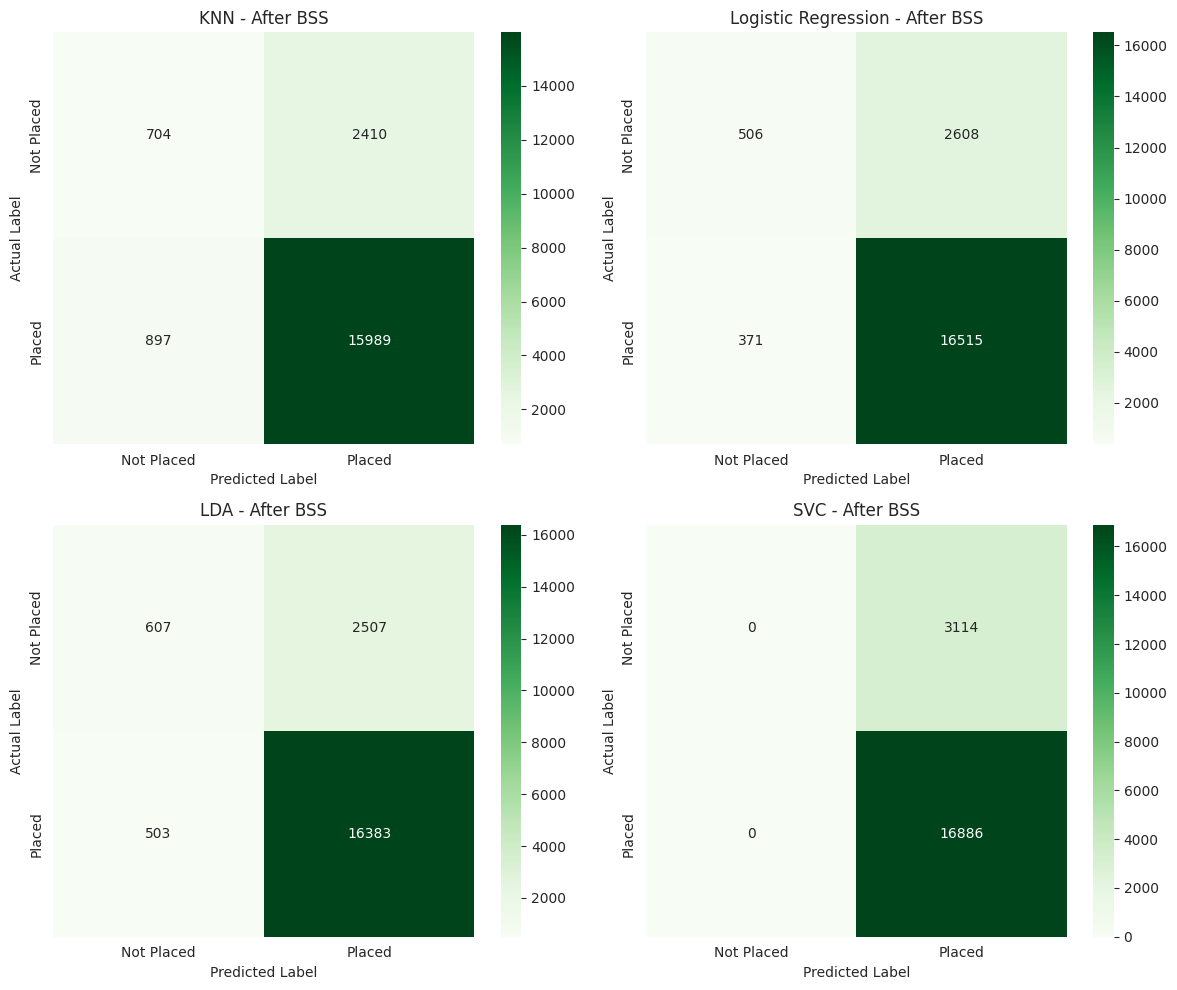

In [ ]:
# Plotting confusion matrices after feature selection
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, name in zip(axes, best_feature_subsets):

    cm = confusion_matrix(
        y_test,
        bss_predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Greens',
        xticklabels=['Not Placed', 'Placed'],
        yticklabels=['Not Placed', 'Placed'],
        ax=ax
    )

    ax.set_title(f'{name} - After BSS')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

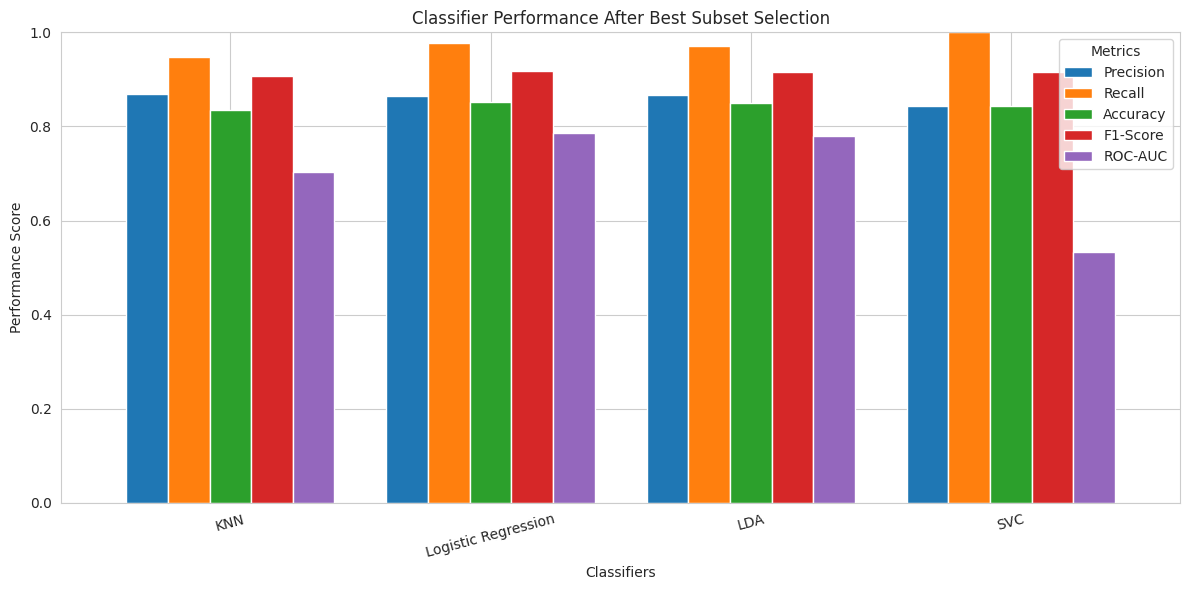

In [ ]:
# Selecting evaluation metrics
bss_metrics = bss_performance_df[
    ['Precision', 'Recall', 'Accuracy', 'F1-Score', 'ROC-AUC']
]

# Plotting metric comparison
bss_metrics.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title("Classifier Performance After Best Subset Selection")
plt.xlabel("Classifiers")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

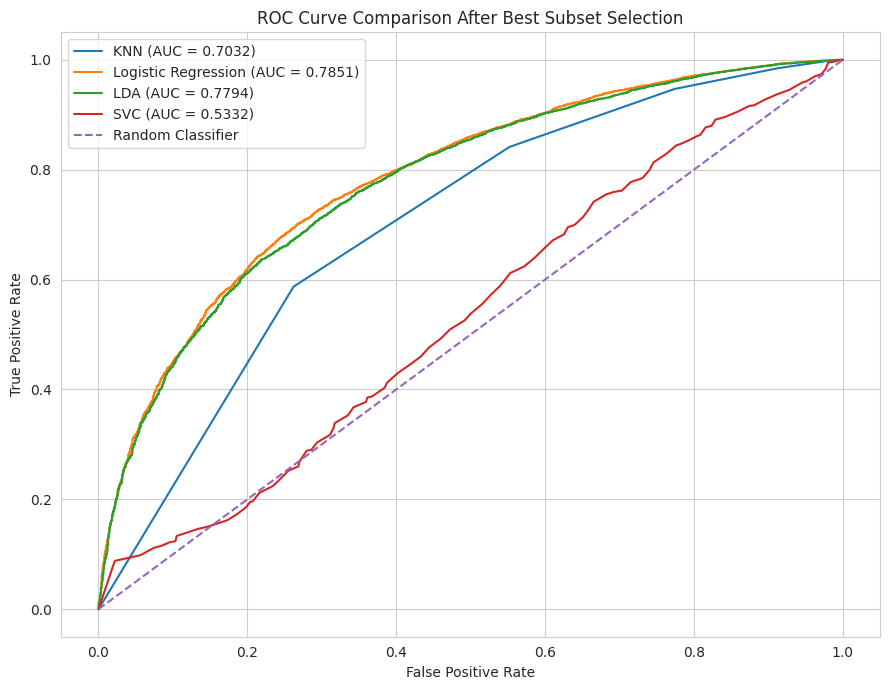

In [ ]:
plt.figure(figsize=(9, 7))

for name in best_feature_subsets:

    fpr, tpr, thresholds = roc_curve(
        y_test,
        bss_prediction_scores[name]
    )

    auc_value = roc_auc_score(
        y_test,
        bss_prediction_scores[name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title("ROC Curve Comparison After Best Subset Selection")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

Accuracy Comparison Before and After BSS:


,Before BSS,After BSS
KNN,0.8377,0.8346
Logistic Regression,0.8586,0.8510
LDA,0.8574,0.8495
SVC,0.8443,0.8443


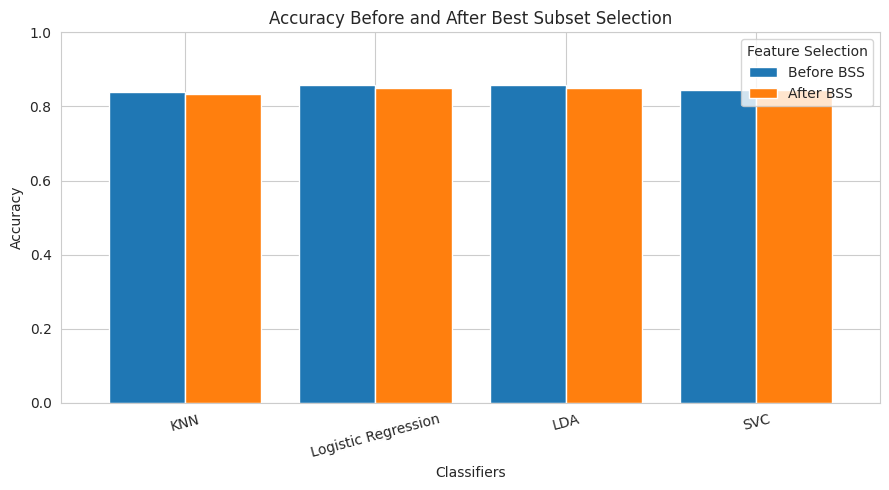

In [ ]:
# Comparing accuracy before and after feature selection
accuracy_comparison = pd.DataFrame({
    'Before BSS': performance_df['Accuracy'],
    'After BSS': bss_performance_df['Accuracy']
})

print("Accuracy Comparison Before and After BSS:")
display(accuracy_comparison.round(4))

# Plotting accuracy comparison
accuracy_comparison.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.8
)

plt.title("Accuracy Before and After Best Subset Selection")
plt.xlabel("Classifiers")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Feature Selection")
plt.tight_layout()
plt.show()

In [ ]:
# Combining performance metrics
comparison_metrics = [
    'Precision',
    'Recall',
    'Accuracy',
    'F1-Score',
    'ROC-AUC'
]

before_after_results = []

for name in classifiers:

    for metric in comparison_metrics:

        before_after_results.append({
            'Classifier': name,
            'Metric': metric,
            'Before BSS': performance_df.loc[name, metric],
            'After BSS': bss_performance_df.loc[name, metric]
        })

before_after_df = pd.DataFrame(before_after_results)

print("Detailed Performance Comparison:")
display(before_after_df.round(4))

Detailed Performance Comparison:


,Classifier,Metric,Before BSS,After BSS
0,KNN,Precision,0.8607,0.8690
1,KNN,Recall,0.9638,0.9469
2,KNN,Accuracy,0.8377,0.8346
3,KNN,F1-Score,0.9093,0.9063
4,KNN,ROC-AUC,0.6943,0.7032
5,Logistic Regression,Precision,0.8756,0.8636
6,Logistic Regression,Recall,0.9703,0.9780
7,Logistic Regression,Accuracy,0.8586,0.8510
8,Logistic Regression,F1-Score,0.9206,0.9173
9,Logistic Regression,ROC-AUC,0.8419,0.7851


In [ ]:
print("FINAL CONCLUSION \n")

print("1. Performance Before Best Subset Selection:\n")

for metric in [
    'Precision',
    'Recall',
    'Accuracy',
    'F1-Score',
    'ROC-AUC'
]:

    best_model = performance_df[metric].idxmax()
    best_score = performance_df.loc[best_model, metric]

    print(
        f"Best {metric}: {best_model} "
        f"({best_score:.4f})"
    )

print("\n2. Performance After Best Subset Selection:\n")

for metric in [
    'Precision',
    'Recall',
    'Accuracy',
    'F1-Score',
    'ROC-AUC'
]:

    best_model = bss_performance_df[metric].idxmax()
    best_score = bss_performance_df.loc[best_model, metric]

    print(
        f"Best {metric}: {best_model} "
        f"({best_score:.4f})"
    )

print("\n3. Best Feature Subsets:\n")

for name, features in best_feature_subsets.items():

    print(f"{name}:")
    print("Selected Features:", features)
    print("Number of Features:", len(features))
    print(
        "5-Fold CV Accuracy:",
        round(
            bss_bss_accuracy if False else {
                'KNN': knn_bss_results,
                'Logistic Regression': lr_bss_results,
                'LDA': lda_bss_results,
                'SVC': svc_bss_results
            }[name]['CV Accuracy'].max(),
            4
        )
    )
    print()

FINAL CONCLUSION 

1. Performance Before Best Subset Selection:

Best Precision: LDA (0.8762)
Best Recall: SVC (1.0000)
Best Accuracy: Logistic Regression (0.8586)
Best F1-Score: Logistic Regression (0.9206)
Best ROC-AUC: Logistic Regression (0.8419)

2. Performance After Best Subset Selection:

Best Precision: KNN (0.8690)
Best Recall: SVC (1.0000)
Best Accuracy: Logistic Regression (0.8510)
Best F1-Score: Logistic Regression (0.9173)
Best ROC-AUC: Logistic Regression (0.7851)

3. Best Feature Subsets:

KNN:
Selected Features: ['communication_score', 'backlogs', 'internships_count', 'hsc_percentage']
Number of Features: 4
5-Fold CV Accuracy: 0.846

Logistic Regression:
Selected Features: ['soft_skills_score', 'communication_score', 'backlogs', 'hsc_percentage']
Number of Features: 4
5-Fold CV Accuracy: 0.856

LDA:
Selected Features: ['communication_score', 'backlogs', 'hsc_percentage']
Number of Features: 3
5-Fold CV Accuracy: 0.8544

SVC:
Selected Features: ['soft_skills_score']
Numb

# Srabani Khuntia, 24BCSB03
# Roll No: 7, Group:E1